## Import the nessisary packages

In [1]:
import numpy as np
import matplotlib

import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
	
# Set such that PDF fonts export in a manner that they
# are editable in illustrator/affinity
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# set to define axes linewidths
matplotlib.rcParams['axes.linewidth'] = 0.5

# this defines some prefactors so inline figures look nice
# on a retina macbook. These can be commented out without any
# issue and are solely asthetic.
%matplotlib inline
%config InlineBackend.figure_format='retina'

# UPDATE 2020-12-31 (my preferred font is Avenir...)
font = {'family' : 'avenir',
    	'weight' : 'normal'}

matplotlib.rc('font', **font)


from scipy.signal import savgol_filter

FINCHES imports. The two frontend objects do the calculations; `domain_analysis` and `chemical_context_seq_plot` are the interpretation tools used at the end of the notebook.

In [2]:
import metapredict as meta
from finches.frontend.mpipi_frontend import Mpipi_frontend
from finches.frontend.calvados_frontend import CALVADOS_frontend
from finches.domain_decomposition import domain_analysis
from finches.frontend.interlogo import chemical_context_seq_plot

## Overview of How Finches Works
Under the hood, finches is built on a forcefield object (Mpipi_model, CALVADOS_model, or your own model built on ForcefieldModel) which has its interaction properties called on by an object that handles the calculations (InteractionMatrixConstructor). The force field and calculation object get combined into a frontend object (FinchesFrontend, Mpipi_frontend, CALVADOS_frontend). This allows the user to think of the calculations they can do with this package as one object. Various functions can be called from this object (without the need to specify all the properties of the predefined forcefield) for fast calculation and visualization of results. In order to use these you need to import them from the finches front end and then initialize them with the parameters you want to use. 

Note: The parameters are only as accurate as the forcefields themselves. For example, the salt you concentrations are "bulk" salt and look to get the interactions on average correct.

In [3]:
#Both of the following are initialized with their default values.
#These could be initialized with nothing in the parenthesis

#initialize a version of the calculations that are based on the Mpipi forcefield
#mf = Mpipi_frontend() #this is an equivilent way to do this
#Roughly physiologic salt, roughly waters dielectric
mf = Mpipi_frontend(salt=0.150, dielectric=80.0) #Salt in M; dielectric is arbitrary units

#initialize a version of the calculations that are based on the Calvados forcfield
#cf = CALVADOS_frontend() #this is an equivilent way to do this
#Roughly physiologic salt, roughly physiologic pH, around room temperature
cf = CALVADOS_frontend(salt=0.150, pH=7.4, temperature=288) #Salt in "M"; pH is "logarithmic units"; temperature in K

## Loading Sequences to Display Examples

In [4]:
#GS linker
GS_LINKER = 20*'GS'


# med sequence (not a TF so not in the dataset...)
med1 = 'MKAQGETEESEKLSKMSSLLERLHAKFNQNRPWSETIKLVRQVMEKRVVMSSGGHQHLVSCLETLQKALKVTSLPAMTDRLESIARQNGLGSHLSASGTECYITSDMFYVEVQLDPAGQLCDVKVAHHGENPVSCPELVQQLREKNFDEFSKHLKGLVNLYNLPGDNKLKTKMYLALQSLEQDLSKMAIMYWKATNAGPLDKILHGSVGYLTPRSGGHLMNLKYYVSPSDLLDDKTASPIILHENNVSRSLGMNASVTIEGTSAVYKLPIAPLIMGSHPVDNKWTPSFSSITSANSVDLPACFFLKFPQPIPVSRAFVQKLQNCTGIPLFETQPTYAPLYELITQFELSKDPDPIPLNHNMRFYAALPGQQHCYFLNKDAPLPDGRSLQGTLVSKITFQHPGRVPLILNLIRHQVAYNTLIGSCVKRTILKEDSPGLLQFEVCPLSESRFSVSFQHPVNDSLVCVVMDVQDSTHVSCKLYKGLSDALICTDDFIAKVVQRCMSIPVTMRAIRRKAETIQADTPALSLIAETVEDMVKKNLPPASSPGYGMTTGNNPMSGTTTPTNTFPGGPITTLFNMSMSIKDRHESVGHGEDFSKVSQNPILTSLLQITGNGGSTIGSSPTPPHHTPPPVSSMAGNTKNHPMLMNLLKDNPAQDFSTLYGSSPLERQNSSSGSPRMEICSGSNKTKKKKSSRLPPEKPKHQTEDDFQRELFSMDVDSQNPIFDVNMTADTLDTPHITPAPSQCSTPPTTYPQPVPHPQPSIQRMVRLSSSDSIGPDVTDILSDIAEEASKLPSTSDDCPAIGTPLRDSSSSGHSQSTLFDSDVFQTNNNENPYTDPADLIADAAGSPSSDSPTNHFFHDGVDFNPDLLNSQSQSGFGEEYFDESSQSGDNDDFKGFASQALNTLGVPMLGGDNGETKFKGNNQADTVDFSIISVAGKALAPADLMEHHSGSQGPLLTTGDLGKEKTQKRVKEGNGTSNSTLSGPGLDSKPGKRSRTPSNDGKSKDKPPKRKKADTEGKSPSHSSSNRPFTPPTSTGGSKSPGSAGRSQTPPGVATPPIPKITIQIPKGTVMVGKPSSHSQYTSSGSVSSSGSKSHHSHSSSSSSSASTSGKMKSSKSEGSSSSKLSSSMYSSQGSSGSSQSKNSSQSGGKPGSSPITKHGLSSGSSSTKMKPQGKPSSLMNPSLSKPNISPSHSRPPGGSDKLASPMKPVPGTPPSSKAKSPISSGSGGSHMSGTSSSSGMKSSSGLGSSGSLSQKTPPSSNSCTASSSSFSSSGSSMSSSQNQHGSSKGKSPSRNKKPSLTAVIDKLKHGVVTSGPGGEDPLDGQMGVSTNSSSHPMSSKHNMSGGEFQGKREKSDKDKSKVSTSGSSVDSSKKTSESKNVGSTGVAKIIISKHDGGSPSIKAKVTLQKPGESSGEGLRPQMASSKNYGSPLISGSTPKHERGSPSHSKSPAYTPQNLDSESESGSSIAEKSYQNSPSSDDGIRPLPEYSTEKHKKHKKEKKKVKDKDRDRDRDKDRDKKKSHSIKPESWSKSPISSDQSLSMTSNTILSADRPSRLSPDFMIGEEDDDLMDVALIGN'

# IDR 
med1_idr = med1[537:]

# IDRs from med14 and med15; nb med15 seems to generally be the most attractive
med14_idr = 'QDARRRSVNEDDNPPSPIGGDMMDSLISQLQPPPQQQPFPKQPGTSGAYPLTSPPTSYHSTVNQSPSMMHTQSPGNLHAASSPSGALRAPSPASFVPTPPPSSHGISIGPGASFASPHGTLDPSSPYTMVSPSGRAGNWPGSPQVSGPSPAARMPGMSPANPSLHSPVPDASHSPRAGTSSQTMPTNMPPPRKLPQRSWAAS'
med15_idr = 'KSQASVSDPMNALQSLTGGPAAGAAGIGMPPRGPGQSLGGMGSLGAMGQPMSLSGQPPPGTSGMAPHSMAVVSTATPQTQLQLQQVALQQQQQQQQFQQQQQAALQQQQQQQQQQQFQAQQSAMQQQFQAVVQQQQQLQQQQQQQQHLIKLHHQNQQQIQQQQQQLQRIAQLQLQQQQQQQQQQQQQQQQALQAQPPIQQPPMQQPQPPPSQALPQQLQQMHHTQHHQPPPQPQQPPVAQNQPSQLPPQSQTQPLVSQAQALPGQMLYTQPPLKFVRAPMVVQQPPVQPQVQQQQTAVQTAQAAQMVAPGVQMITEALAQGGMHIRARFPPTTAVSAIPSSSIPLGRQPMAQVSQSSLPMLSSPSPGQQVQTPQSMPPPPQPSPQPGQPSSQPNSNVSSGPAPSPSSFLPSPSPQPSQSPVTARTPQNFSVPSPGPLNTPVNPSSVMSPAGSSQA'


## Calculating an epsilon value
An epsilon value is aimed at getting at overall attractive or repulsiveness between two interacting IDR sequences. Since it is designed to get at interaction it is convienent to think of this value as a proxy for energy difference to have these two IDRs go from unbound to bound (at equilibrium and in the context of the solvent). This can help in understanding what the realative magnitudes of the these values mean.

Note: these calculation could be performed with calvados forcefiled by simply switching "mf" for "cf".

In [5]:
#calculate the interaction for med1_idr with med14_idr and then med15_idr

#med1_idr interacts with med14_idr
interact1 = mf.epsilon(med1_idr,med14_idr)

#med1_idr interacts with med15_idr
interact2 = mf.epsilon(med1_idr,med15_idr)

#print the resulting values
print(f"med1's IDR interacting with | Interaction Value")
print(f"med14's IDR                   {interact1}")
print(f"med15's IDR                   {interact2}")

med1's IDR interacting with | Interaction Value
med14's IDR                   37.7751986092282
med15's IDR                   25.937027862166502


Based on the above results med1's IDR is predicted to interact stronger with med15's. This is because like free energies, epsilon values indicate smaller values as being more attractive. The 0 value is tuned with GS linkers self interactions. This means that GS linkers interacting with themselves will give a 0 value back for the epsilon value.

In [6]:
#calculate the epsilon value for a GS linker
gs_interaction = mf.epsilon(GS_LINKER, GS_LINKER)
print(f"The GS linker epsilon interaction value is {gs_interaction}.\nThis is close to 0")

The GS linker epsilon interaction value is 1.451761984938571e-05.
This is close to 0


The epsilon value is dependant on order. This is because it is an "extrinsic" calculation. Flipping the order will yeild different values. The way to think about this is that you are taking the first sequence and "bathing" it in the second sequence.

In [7]:
#med1_idr interacts with med14_idr
interact1 = mf.epsilon(med1_idr,med14_idr)

#flip the order of the interaction
interact1_flipped = mf.epsilon(med14_idr,med1_idr)

#print the result of flipping the order
print(f"This is the interaction value of med1 bathed in med14: {interact1}")
print(f"This is the interaction value of med14 bathed in med1: {interact1_flipped}")
print(f"Note that these are different values.")

This is the interaction value of med1 bathed in med14: 37.7751986092282
This is the interaction value of med14 bathed in med1: 7.308994366919638
Note that these are different values.


You can recover an "intrinsic" interaction value by dividing by the sequence length of the first IDR entered. This shows in what way the calculation is "extrinsic". It is so in a sequence length sense.

In [8]:
intrinsic_interact1 = interact1/len(med1_idr)
intrinsic_interact1_flipped = interact1_flipped/len(med14_idr)
print(f"This is the interaction value of med1 bathed in med14 divided by the length of med1's sequence: {intrinsic_interact1}")
print(f"This is the interaction value of med14 bathed in med1 divided by the length of med14's sequence: {intrinsic_interact1_flipped}")
print(f"Notice how the flipped interaction calculation are the same once they are divided by the first sequences length.")

This is the interaction value of med1 bathed in med14 divided by the length of med1's sequence: 0.03618314043029521
This is the interaction value of med14 bathed in med1 divided by the length of med14's sequence: 0.03618314043029524
Notice how the flipped interaction calculation are the same once they are divided by the first sequences length.


The epsilon function assumes all the portions of the sequences are IDRs. If your sequence is not fully an IDR then you will need to truncate it to the portion that is an IDR.

There are correction terms built into the calculation. These are meant to correct for 2 phenomina the baseline forcefield integration does not capture well. The first is an aliphatic correction. Aliphatic residues are more "sticky" that one would expect. This is due to the hydrophobic effect. Clusters of aliphatics are not respresented well by simple two body integration schemes. This gets corrected for under the hood. Another effect that gets corrected for is that charge clusters are less repulsive than they would seem to be from simple two body integration. This is because average radial fields neglect things like the side chain orientation (the ability to spin the charge out of the presense of another charge slightly). You can turn either of these corrections off if you have a need to do that. It is NOT recommended to turn these off unless there is a good reason.

In [9]:
#med1_idr interacts with med14_idr
interact1 = mf.epsilon(med1_idr,med14_idr)

#compute the interaction without the aliphatic correction
interact1_wo_ali = mf.epsilon(med1_idr,med14_idr, use_aliphatic_weighting=False)
#compute the interaction without the charge correction
interact1_wo_charge = mf.epsilon(med1_idr,med14_idr, use_charge_weighting=False)
#compute the interaction without the charge correction
interact1_wo_both = mf.epsilon(med1_idr,med14_idr, use_aliphatic_weighting=False, use_charge_weighting=False)

#print out the results
print(f"Calculation defaults: {interact1}")
print(f"Calculation without aliphatic correction: {interact1_wo_ali}")
print(f"Calculation without charge correction: {interact1_wo_charge}")
print(f"Calculation without both corrections: {interact1_wo_both}")

Calculation defaults: 37.7751986092282
Calculation without aliphatic correction: 39.08934821434127
Calculation without charge correction: 40.63304944025069
Calculation without both corrections: 41.94719904536376


## Epsilon "vector" calculations

The epsilon value is quite useful as it provides gross information about the interaction. However, this does not provide any information about the residue level interaction strength. This is where the epsilon vector calculation comes in handy. Similar to the epsilon value it does not auto parse out non-IDR regions of your sequence so you will need to do that before you can proceed.

In [10]:
#quick example of the epsilon vector calculation
interact1_vec = mf.epsilon_vectors(med1_idr,med14_idr) #[0] = attractive numpy array; [1] = repulsive numpy array
print(interact1_vec[0])

[-0.04026231 -0.19028739  0.03515593 ...  0.00552085 -0.07758284
 -0.19028739]


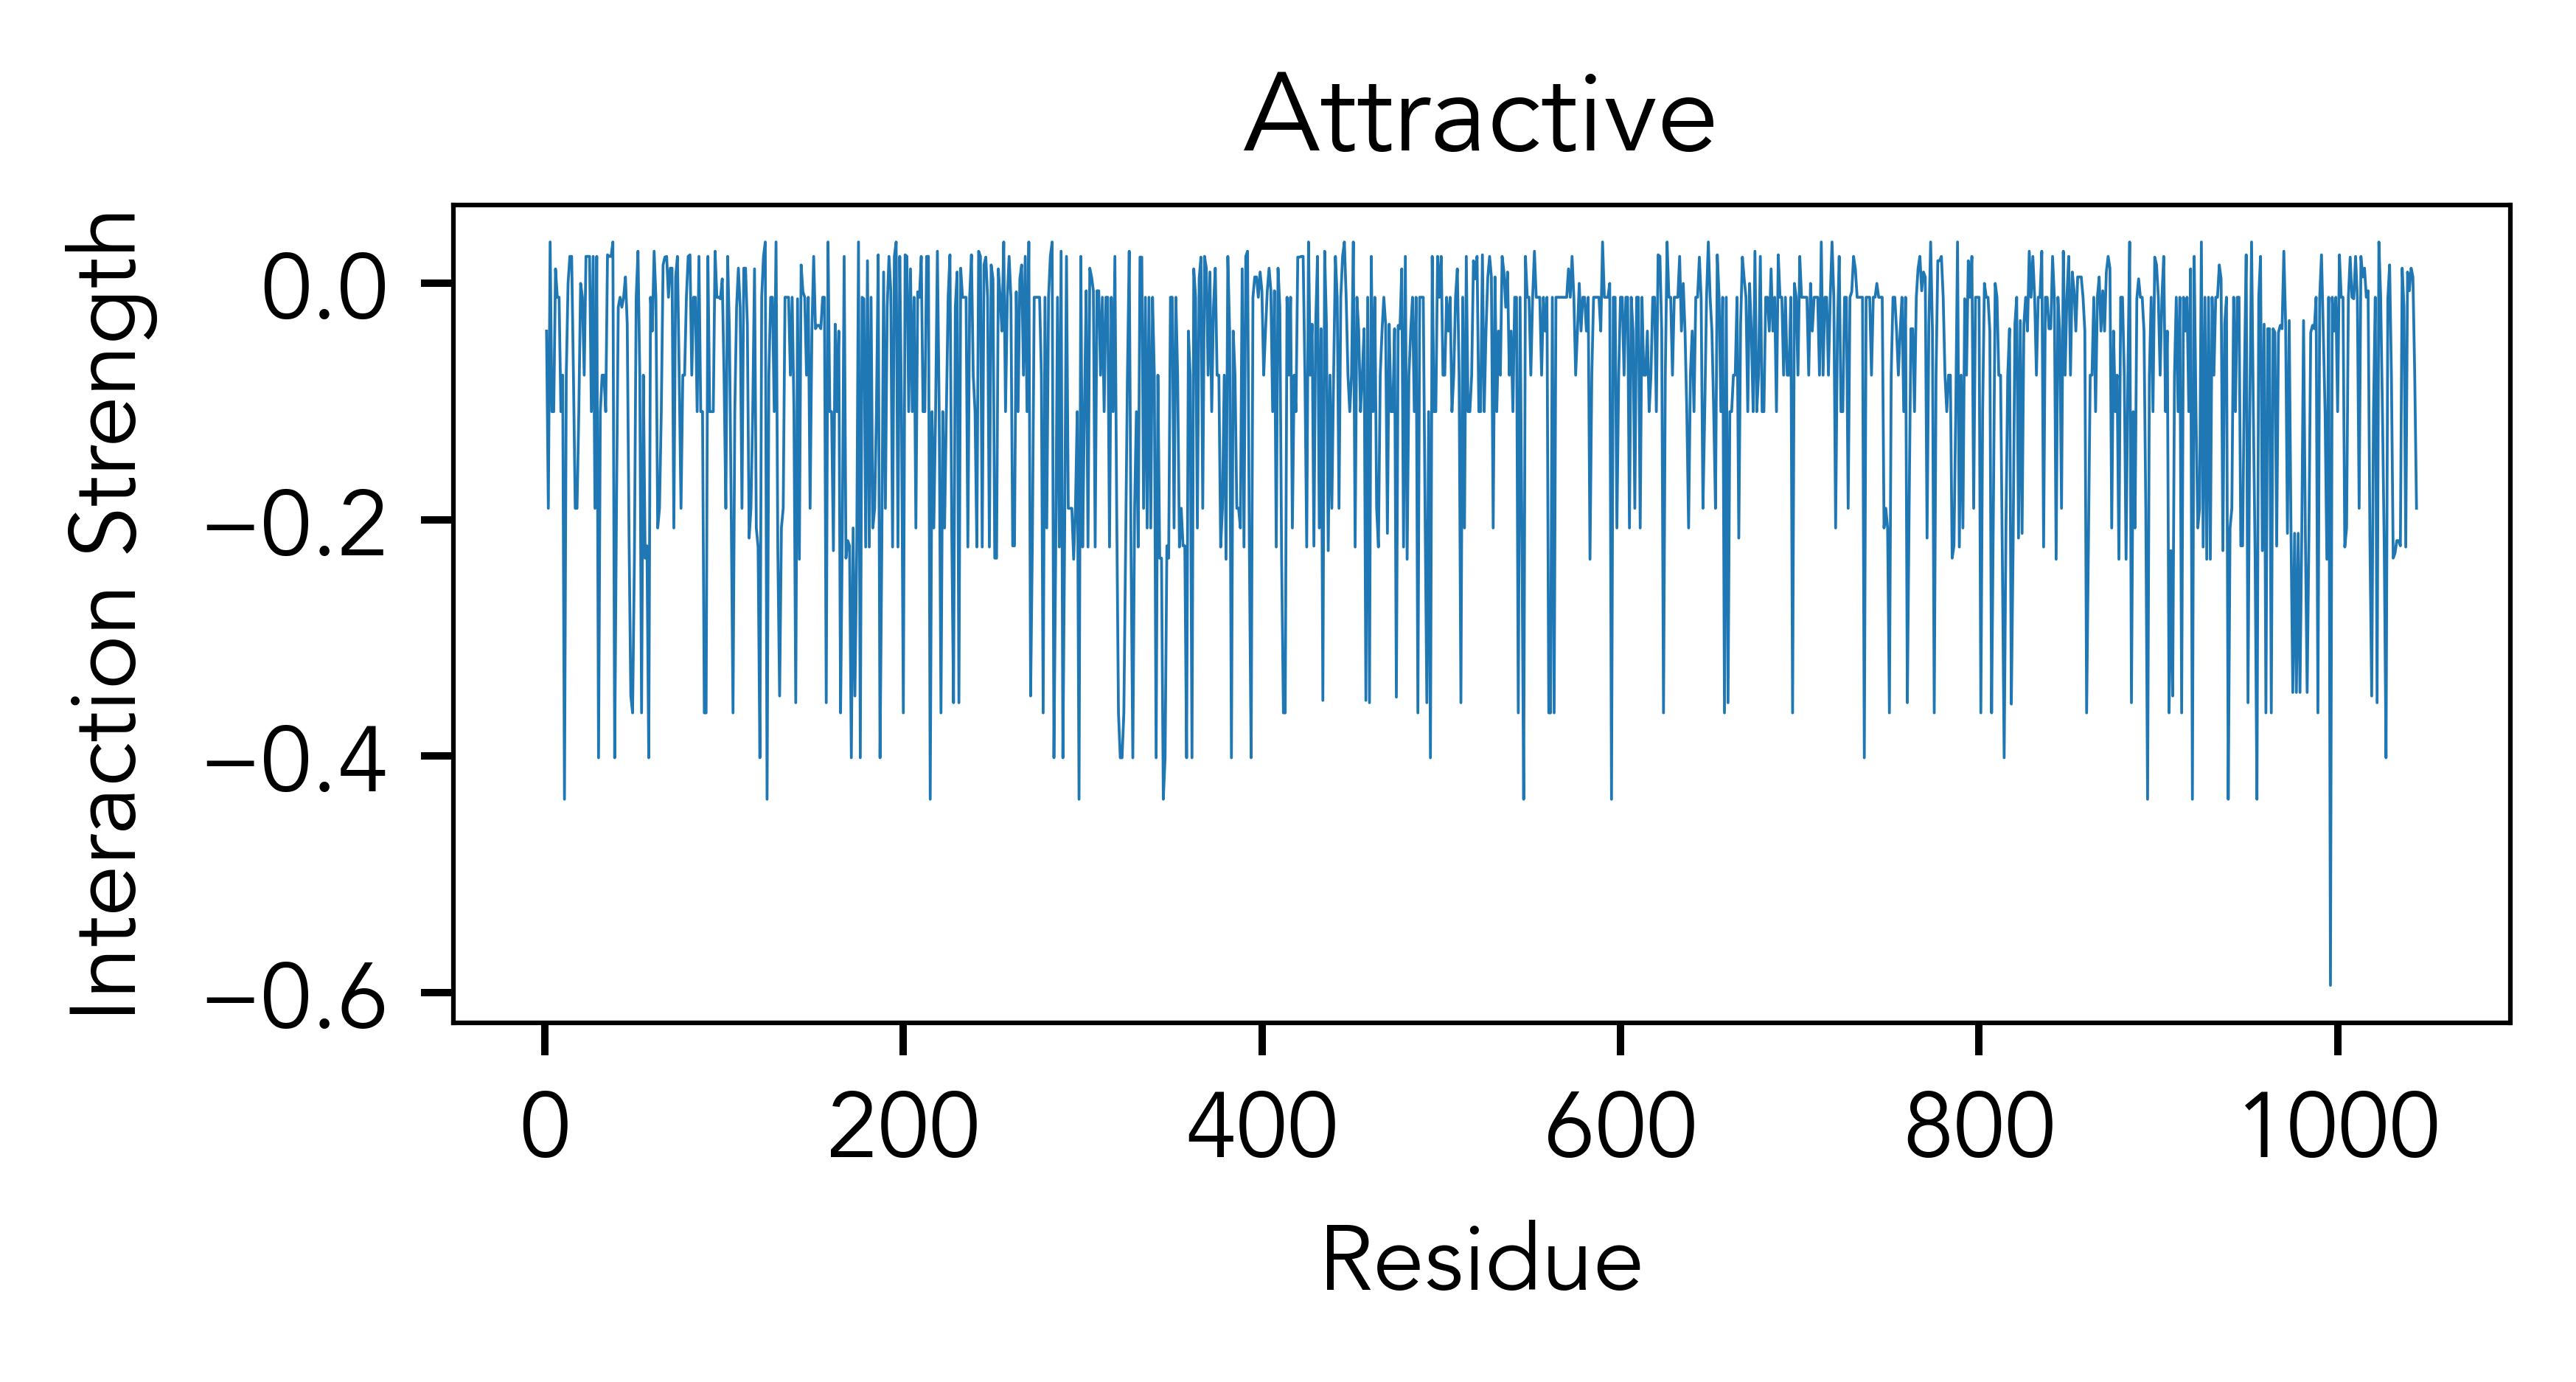

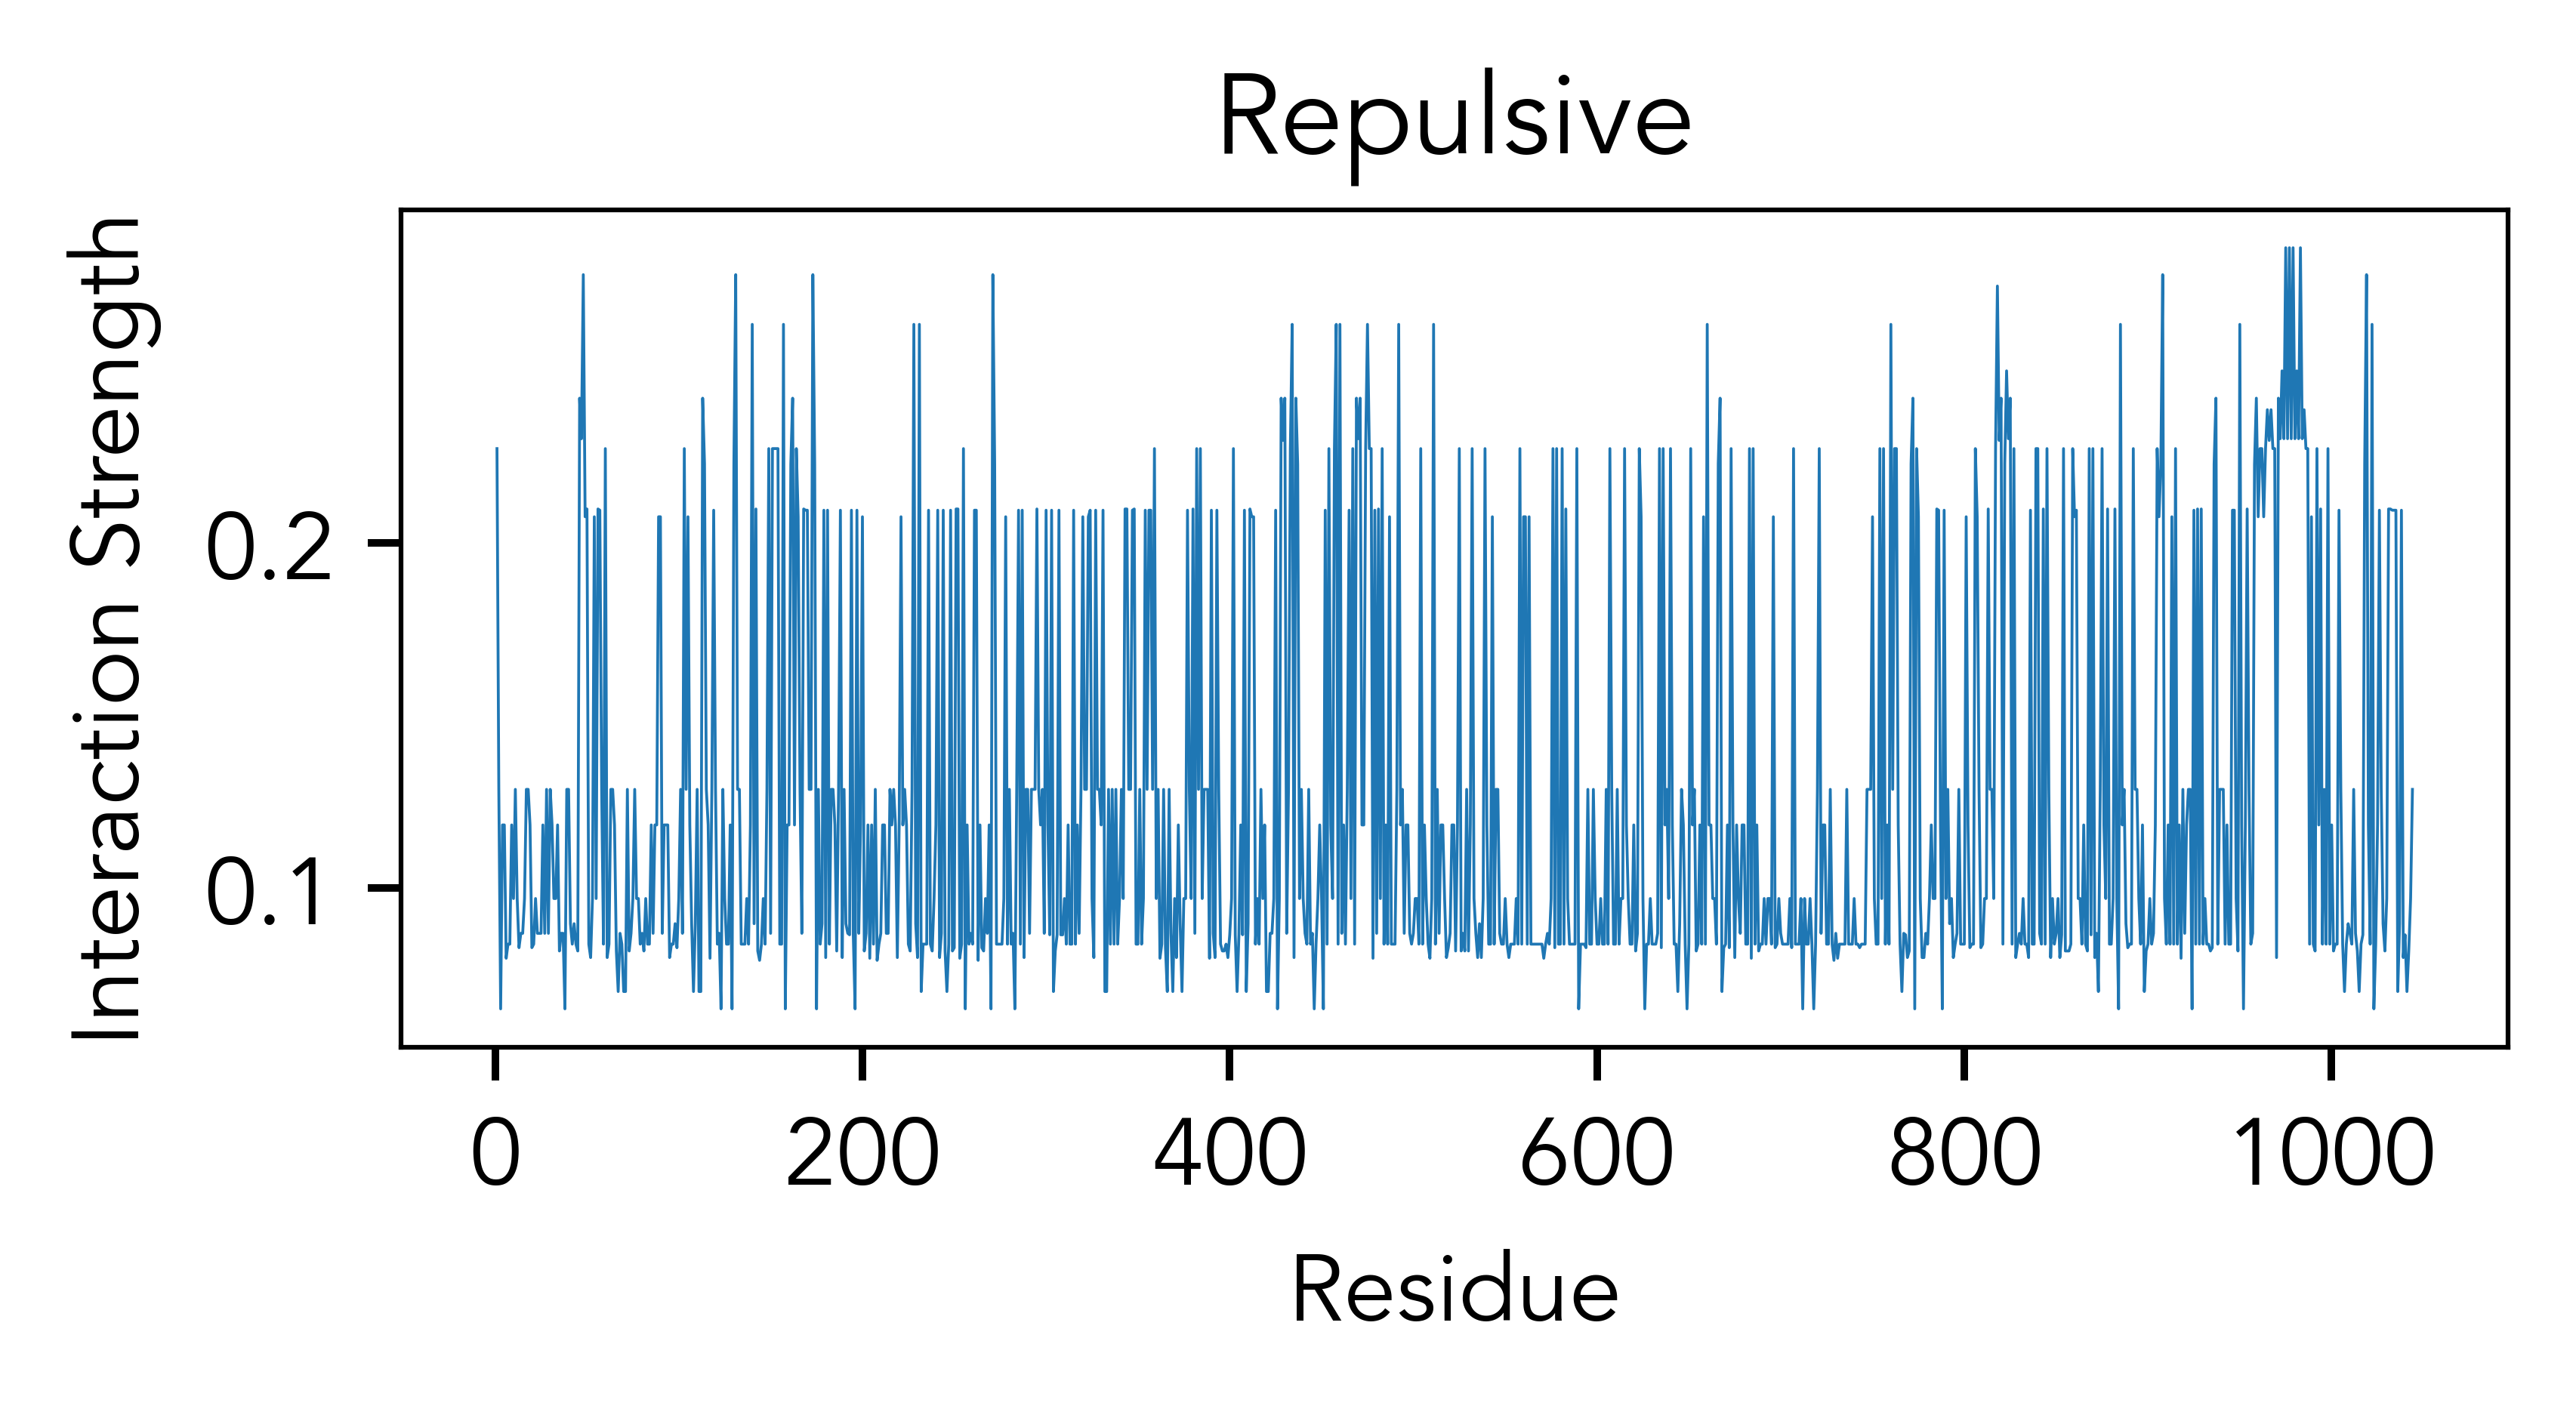

In [11]:
#lets plot the attractive and repulsive portions of the interactions
line_width = 0.3
attractive_vec = interact1_vec[0]
repulsive_vec = interact1_vec[1]
residue_number = np.arange(1,len(attractive_vec)+1)

#Attractive vector plot
fig = plt.figure(figsize=(4, 1.6), dpi=450)
plt.plot(residue_number, attractive_vec,linewidth=line_width)
plt.xlabel(f"Residue")
plt.ylabel(f"Interaction Strength")
plt.title(f"Attractive")
plt.show()
#repulsive vector plot
fig = plt.figure(figsize=(4, 1.6), dpi=450)
plt.plot(residue_number, repulsive_vec,linewidth=line_width)
plt.xlabel(f"Residue")
plt.ylabel(f"Interaction Strength")
plt.title(f"Repulsive")
plt.show()

You can see how the attractive and repuslive values are defined as being below and above 0 respectively. The raw vectors are often not what you will want to plot though. There is a need to smooth the values and combine the attractive and repulsive vectors. It is up to you to determine how to do the filtering and combining. But if you want to follow the methodology of the nucleic interaction vector (will be shown after this), then sum the attractive and repulsive interaction for each residue. Once that is done, then apply a Savgov filter. I outline this below.

In [12]:
#lets combine and smooth the attractive/repulsive vector as outlined above
#combine the data
combined_vec = attractive_vec + repulsive_vec

#filter with a savgov filter (window size of 30 and order = 3)
filtered_data = savgol_filter(combined_vec, 30, 3)

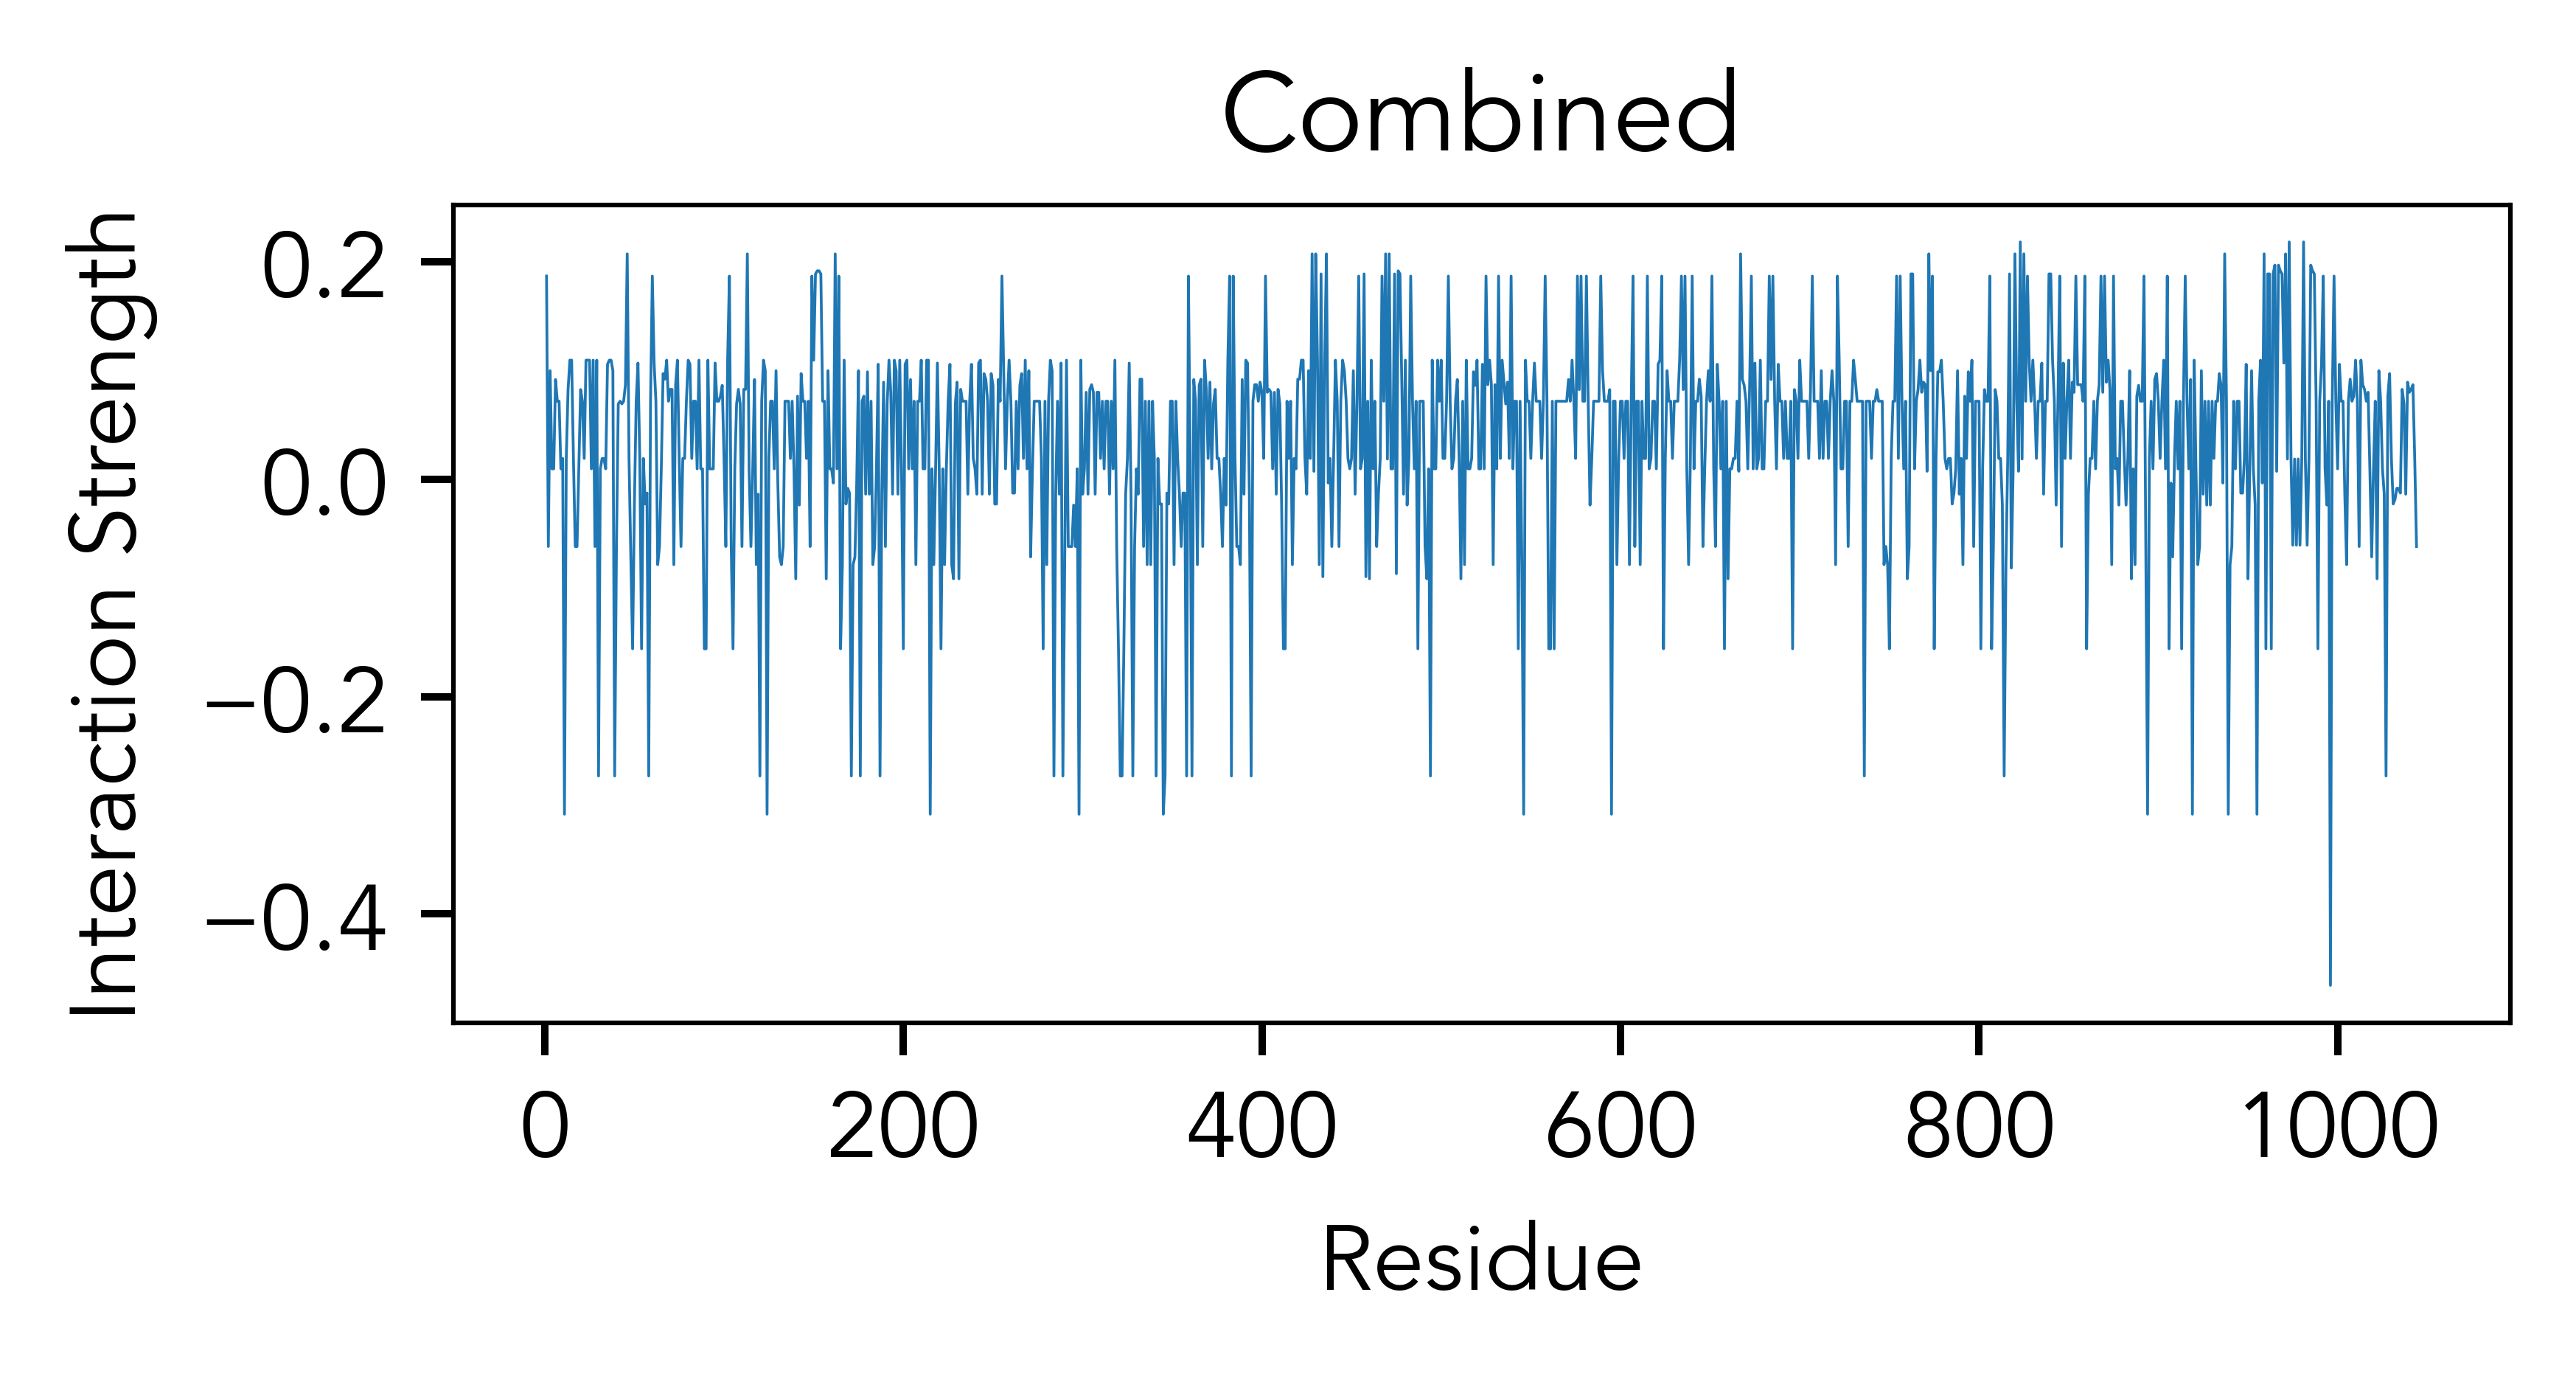

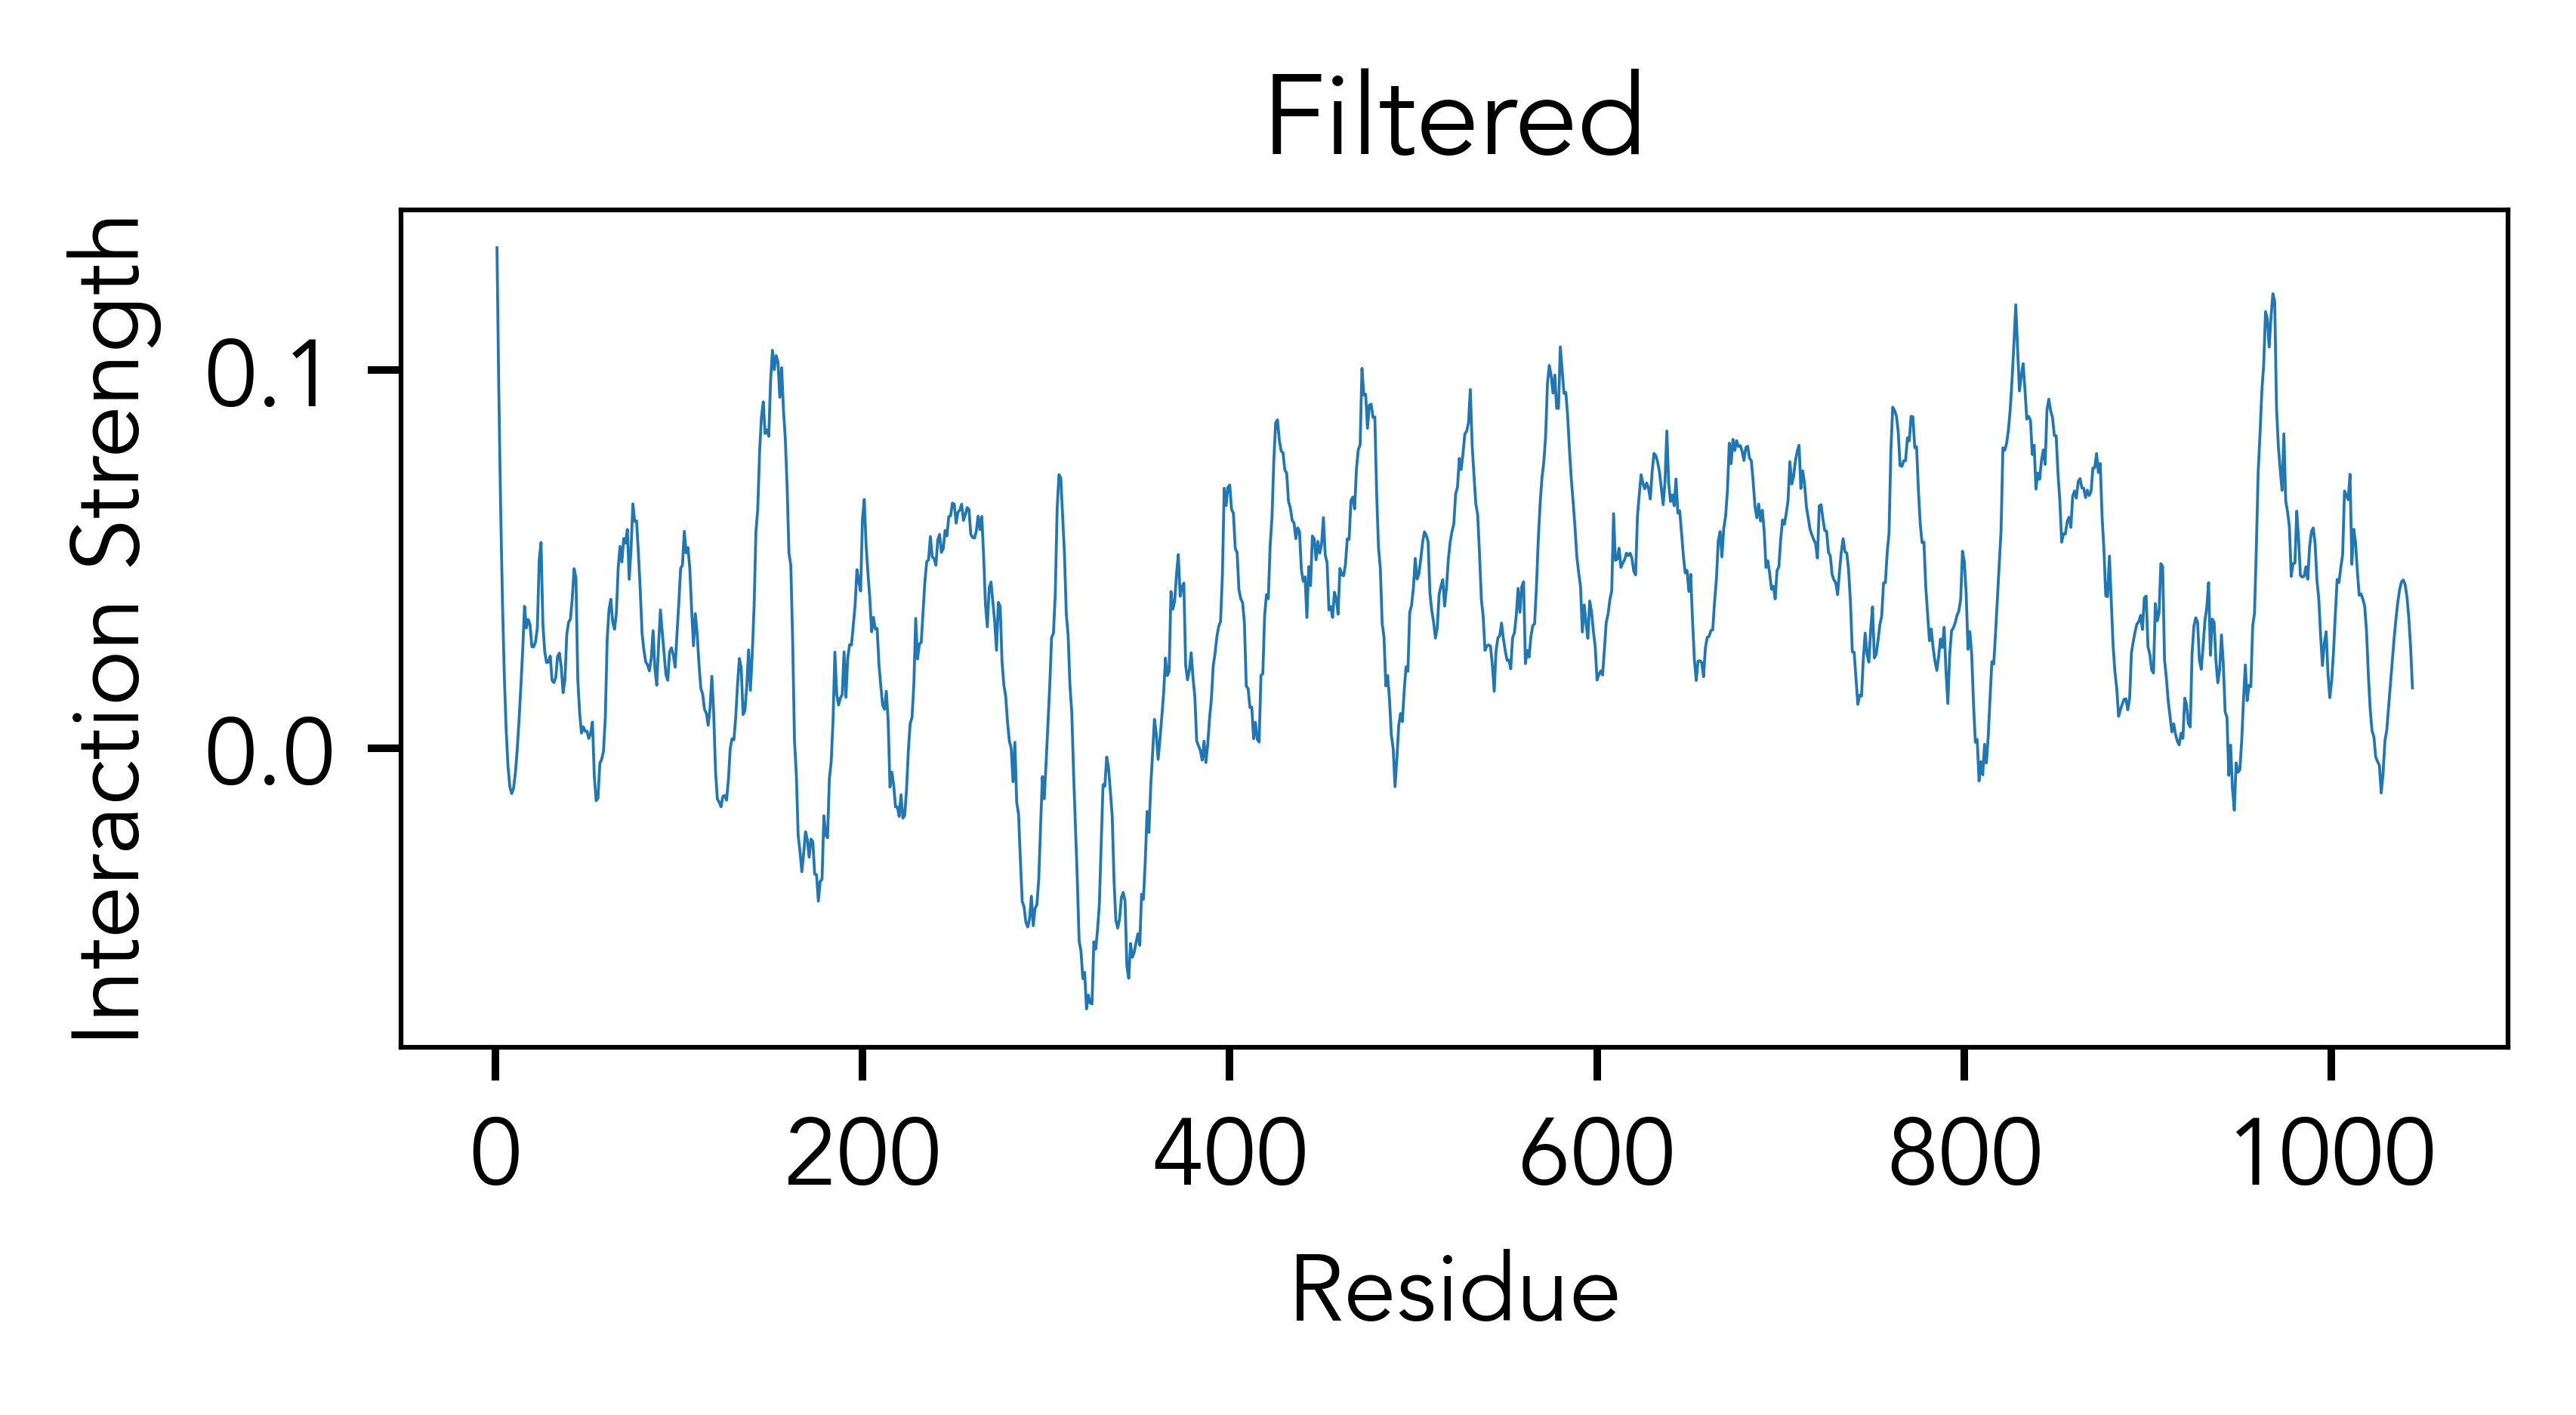

In [13]:
#lets plot the combined and then the fitlered data
fig = plt.figure(figsize=(4, 1.6), dpi=450)
plt.plot(residue_number, combined_vec,linewidth=line_width)
plt.xlabel(f"Residue")
plt.ylabel(f"Interaction Strength")
plt.title(f"Combined")
plt.show()

fig = plt.figure(figsize=(4, 1.6), dpi=450)
plt.plot(residue_number, filtered_data,linewidth=line_width)
plt.xlabel(f"Residue")
plt.ylabel(f"Interaction Strength")
plt.title(f"Filtered")
plt.show()

Notice how the interaction when combined gives you the residue specific attractive versus repulsive portion. While this is potentially useful information, each residue is typically surrounded by other residues and their repulsion could inhibit actual attraction from occuring. Since this is possible, its good to filter the signal first and then try to interpret the result. That is what the bottom plot is doing and it shows that on bulk most of the residues are repulsive except a few sections between ~300-400 residue number.

You can also get a vector form of the epsilon calculation computed on nucleic acids. This is more easily accomplished with a simple method from our MPipi forcefiled frontend object (mf).

[]

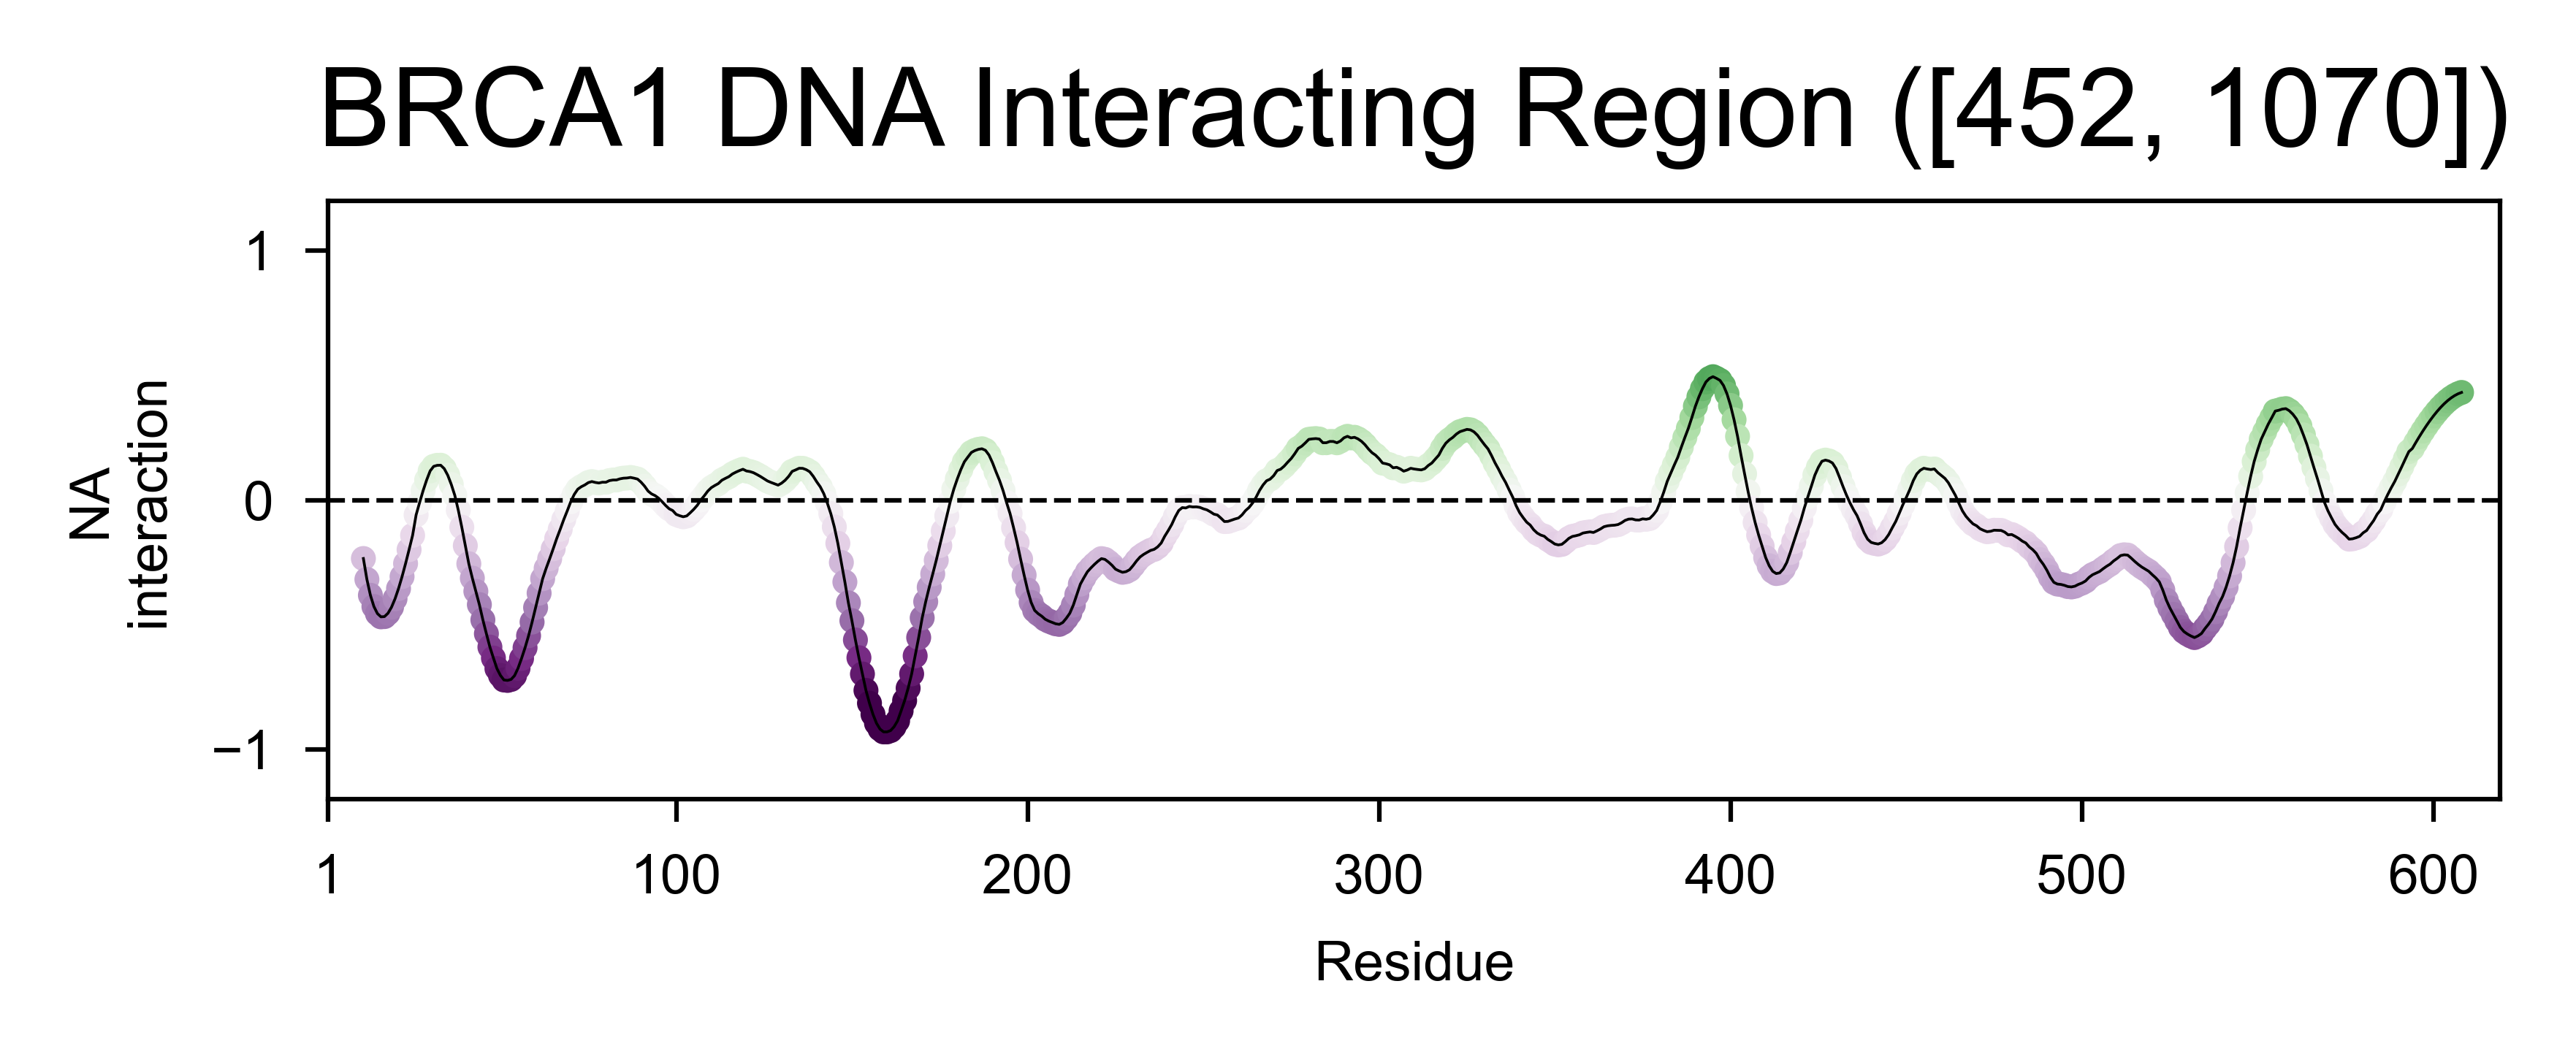

In [14]:
brca1_seq = "MDLSALRVEEVQNVINAMQKILECPICLELIKEPVSTKCDHIFCKFCMLKLLNQKKGPSQCPLCKNDITKRSLQESTRFSQLVEELLKIICAFQLDTGLEYANSYNFAKKENNSPEHLKDEVSIIQSMGYRNRAKRLLQSEPENPSLQETSLSVQLSNLGTVRTLRTKQRIQPQKTSVYIELGSDSSEDTVNKATYCSVGDQELLQITPQGTRDEISLDSAKKAACEFSETDVTNTEHHQPSNNDLNTTEKRAAERHPEKYQGSSVSNLHVEPCGTNTHASSLQHENSSLLLTKDRMNVEKAEFCNKSKQPGLARSQHNRWAGSKETCNDRRTPSTEKKVDLNADPLCERKEWNKQKLPCSENPRDTEDVPWITLNSSIQKVNEWFSRSDELLGSDDSHDGESESNAKVADVLDVLNEVDEYSGSSEKIDLLASDPHEALICKSERVHSKSVESNIEDKIFGKTYRKKASLPNLSHVTENLIIGAFVTEPQIIQERPLTNKLKRKRRPTSGLHPEDFIKKADLAVQKTPEMINQGTNQTEQNGQVMNITNSGHENKTKGDSIQNEKNPNPIESLEKESAFKTKAEPISSSISNMELELNIHNSKAPKKNRLRRKSSTRHIHALELVVSRNLSPPNCTELQIDSCSSSEEIKKKKYNQMPVRHSRNLQLMEGKEPATGAKKSNKPNEQTSKRHDSDTFPELKLTNAPGSFTKCSNTSELKEFVNPSLPREEKEEKLETVKVSNNAEDPKDLMLSGERVLQTERSVESSSISLVPGTDYGTQESISLLEVSTLGKAKTEPNKCVSQCAAFENPKGLIHGCSKDNRNDTEGFKYPLGHEVNHSRETSIEMEESELDAQYLQNTFKVSKRQSFAPFSNPGNAEEECATFSAHSGSLKKQSPKVTFECEQKEENQGKNESNIKPVQTVNITAGFPVVGQKDKPVDNAKCSIKGGSRFCLSSQFRGNETGLITPNKHGLLQNPYRIPPLFPIKSFVKTKCKKNLLEENFEEHSMSPEREMGNENIPSTVSTISRNNIRENVFKEASSSNINEVGSSTNEVGSSINEIGSSDENIQAELGRNRGPKLNAMLRLGVLQPEVYKQSLPGSNCKHPEIKKQEYEEVVQTVNTDFSPYLISDNLEQPMGSSHASQVCSETPDDLLDDGEIKEDTSFAENDIKESSAVFSKSVQKGELSRSPSPFTHTHLAQGYRRGAKKLESSEENLSSEDEELPCFQHLLFGKVNNIPSQSTRHSTVATECLSKNTEENLLSLKNSLNDCSNQVILAKASQEHHLSEETKCSASLFSSQCSELEDLTANTNTQDPFLIGSSKQMRHQSESQGVGLSDKELVSDDEERGTGLEENNQEEQSMDSNLGEAASGCESETSVSEDCSGLSSQSDILTTQQRDTMQHNLIKLQQEMAELEAVLEQHGSQPSNSYPSIISDSSALEDLRNPEQSTSEKAVLTSQKSSEYPISQNPEGLSADKFEVSADSSTSKNKEPGVERSSPSKCPSLDDRWYMHSCSGSLQNRNYPSQEELIKVVDVEEQQLEESGPHDLTETSYLPRQDLEGTPYLESGISLFSDDPESDPSEDRAPESARVGNIPSSTSALKVPQLKVAESAQSPAAAHTTDTAGYNAMEESVSREKPELTASTERVNKRMSMVVSGLTPEEFMLVYKFARKHHITLTNLITEETTHVVMKTDAEFVCERTLKYFLGIAGGKWVVSYFWVTQSIKERKMLNEHDFEVRGDVVNGRNHQGPKRARESQDRKIFRGLEICCYGPFTNMPTDQLEWMVQLCGASVVKELSSFTLGTGVHPIVVVQPDAWTEDNGFHAIGQMCEAPVVTREWVLDSVALYQCQELDTYLIPQIPHSHY"
brca1_dna_interacting_region = [452,1070]
frag_size = 21 #The epsilon value is calculated and normalized for a window of this size.
smoothing_window = 30 #This is the widnow size on the Savgov filter

#get the brca1 dna interacting region
brca1_dna_seq = brca1_seq[brca1_dna_interacting_region[0]:brca1_dna_interacting_region[1]]

#compute the interaction vector and plot it
mf.plot_protein_nucleic_vector(brca1_dna_seq, 
                               fragsize=frag_size,
                               smoothing_window=smoothing_window)
plt.title(f"BRCA1 DNA Interacting Region ({brca1_dna_interacting_region})")
plt.plot()

Before leaving this section, you may be wondering why the IDR-IDR interaction does not have a built in combination and filter method like the nucleic acid vector does. This is because the nucleic acid vector is simply a bulk interaction with a poly U RNA of the same length as your fragment size. All the interaction terms that get computed between an IDR residue and the Poly U result in the same value. This makes it inherently a vector calculation. For the IDR-IDR interaction case, we compute the vectors by averaging the interaction of a single residue against the entire other IDR. This makes the interpretation of a the combined and filtered vector challanging as you do not know how variable the values were around that mean. So while it is possible to combine and filter the IDR-IDR interaction vector, it is not always easily interpretable. Thinking back to the examples above, this should make you question my interpretation about the region I said might interact. In order to see if the interaction vector is reasonable, you would need to look at the interaction matrix which you can also compute and display using finches.

## Interaction Matrix

The intermap is built and drawn by `interaction_figure()`, which returns the figure, the image and the axes `(fig, im, ax_main, ax_top, ax_right, ax_colorbar)`. If you want the raw matrix instead, for example to analyse it yourself, use `intermolecular_idr_matrix()`, which returns `((matrix, seq1_positions, seq2_positions), disorder_1, disorder_2)`.

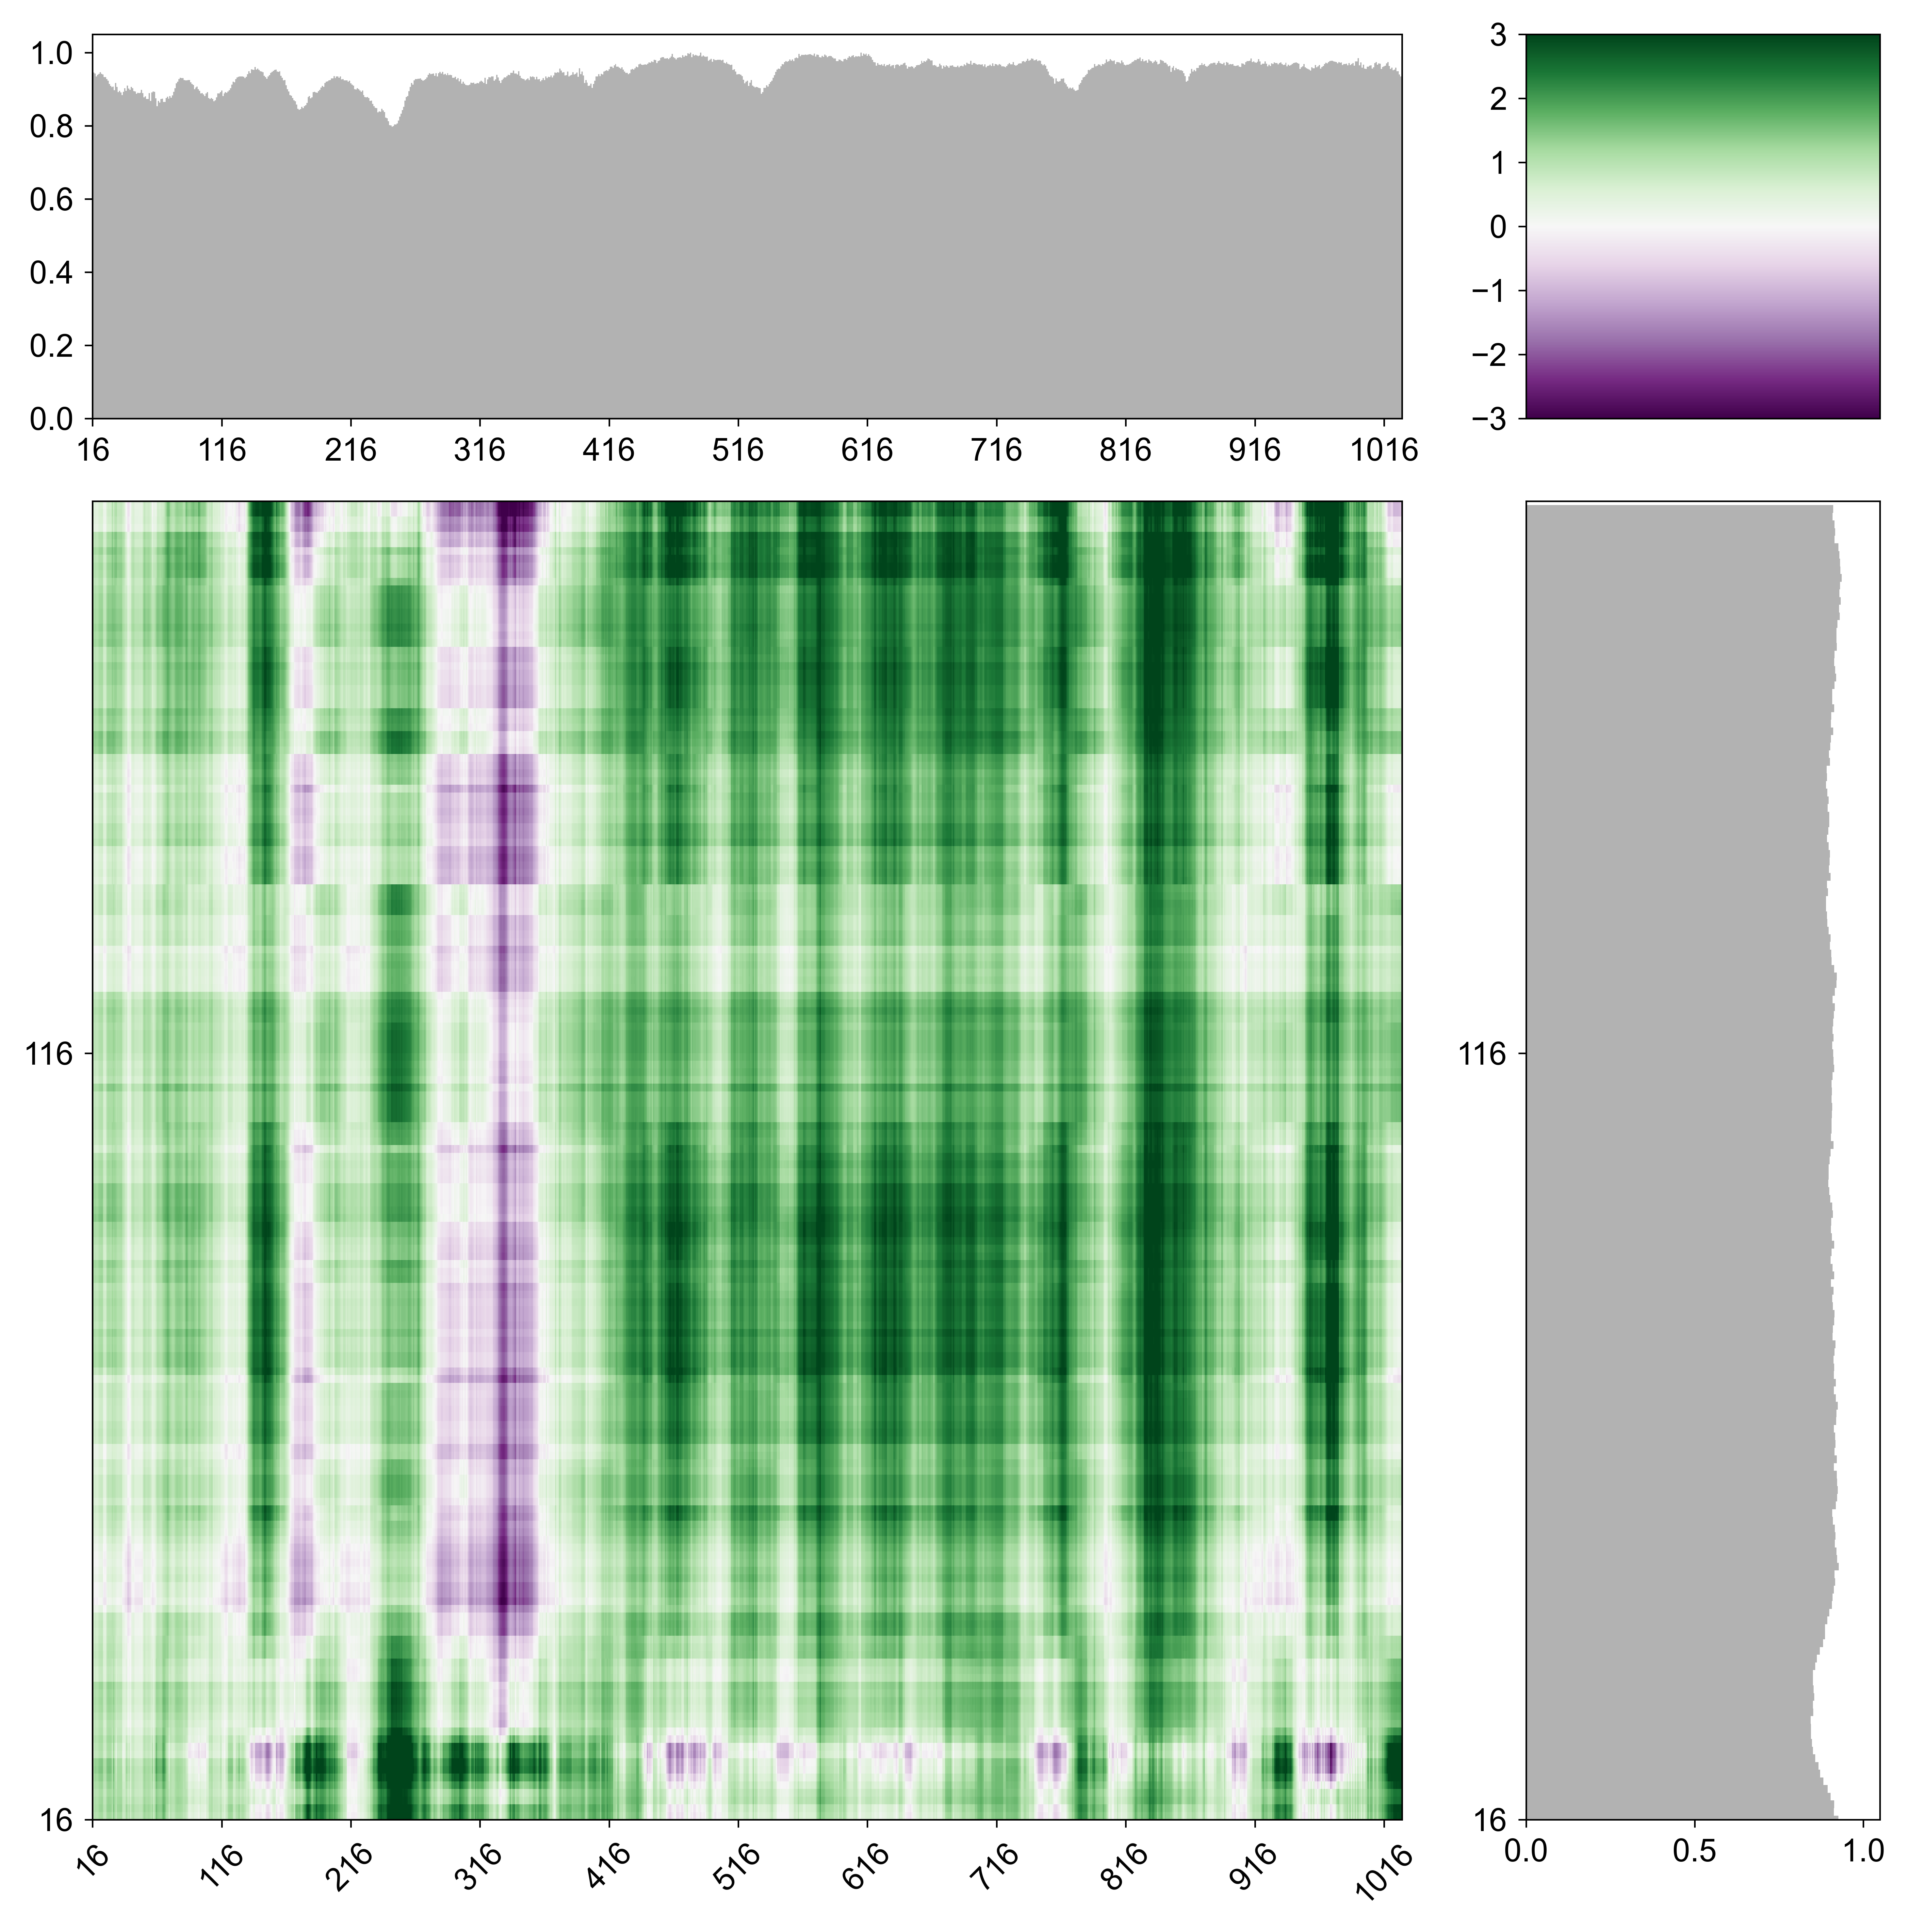

In [15]:
#build and draw the intermap; returns (fig, im, ax_main, ax_top, ax_right, ax_colorbar)
idr_idr_interact = mf.interaction_figure(med1_idr,med14_idr)

Upon inspecting the interaction matrix you can see that the previously described region is largely attractive. This gives a nice method to determine the heterogeneity of an interacting vectors values since we are only privy to the mean.

While these interaction matrixes or maps can be quite useful to understand the interaction vector, they also harbor the potential to identify minor regions of interaction. These are regions that might interact even if it happens relatively infrequently. We have also built tools to aid in identification of regions both at the matrix level and vector level.

## Visuals to aid in interpretation

First we have built methods to automatically detect regions in an interaction map. This works based on two parameters

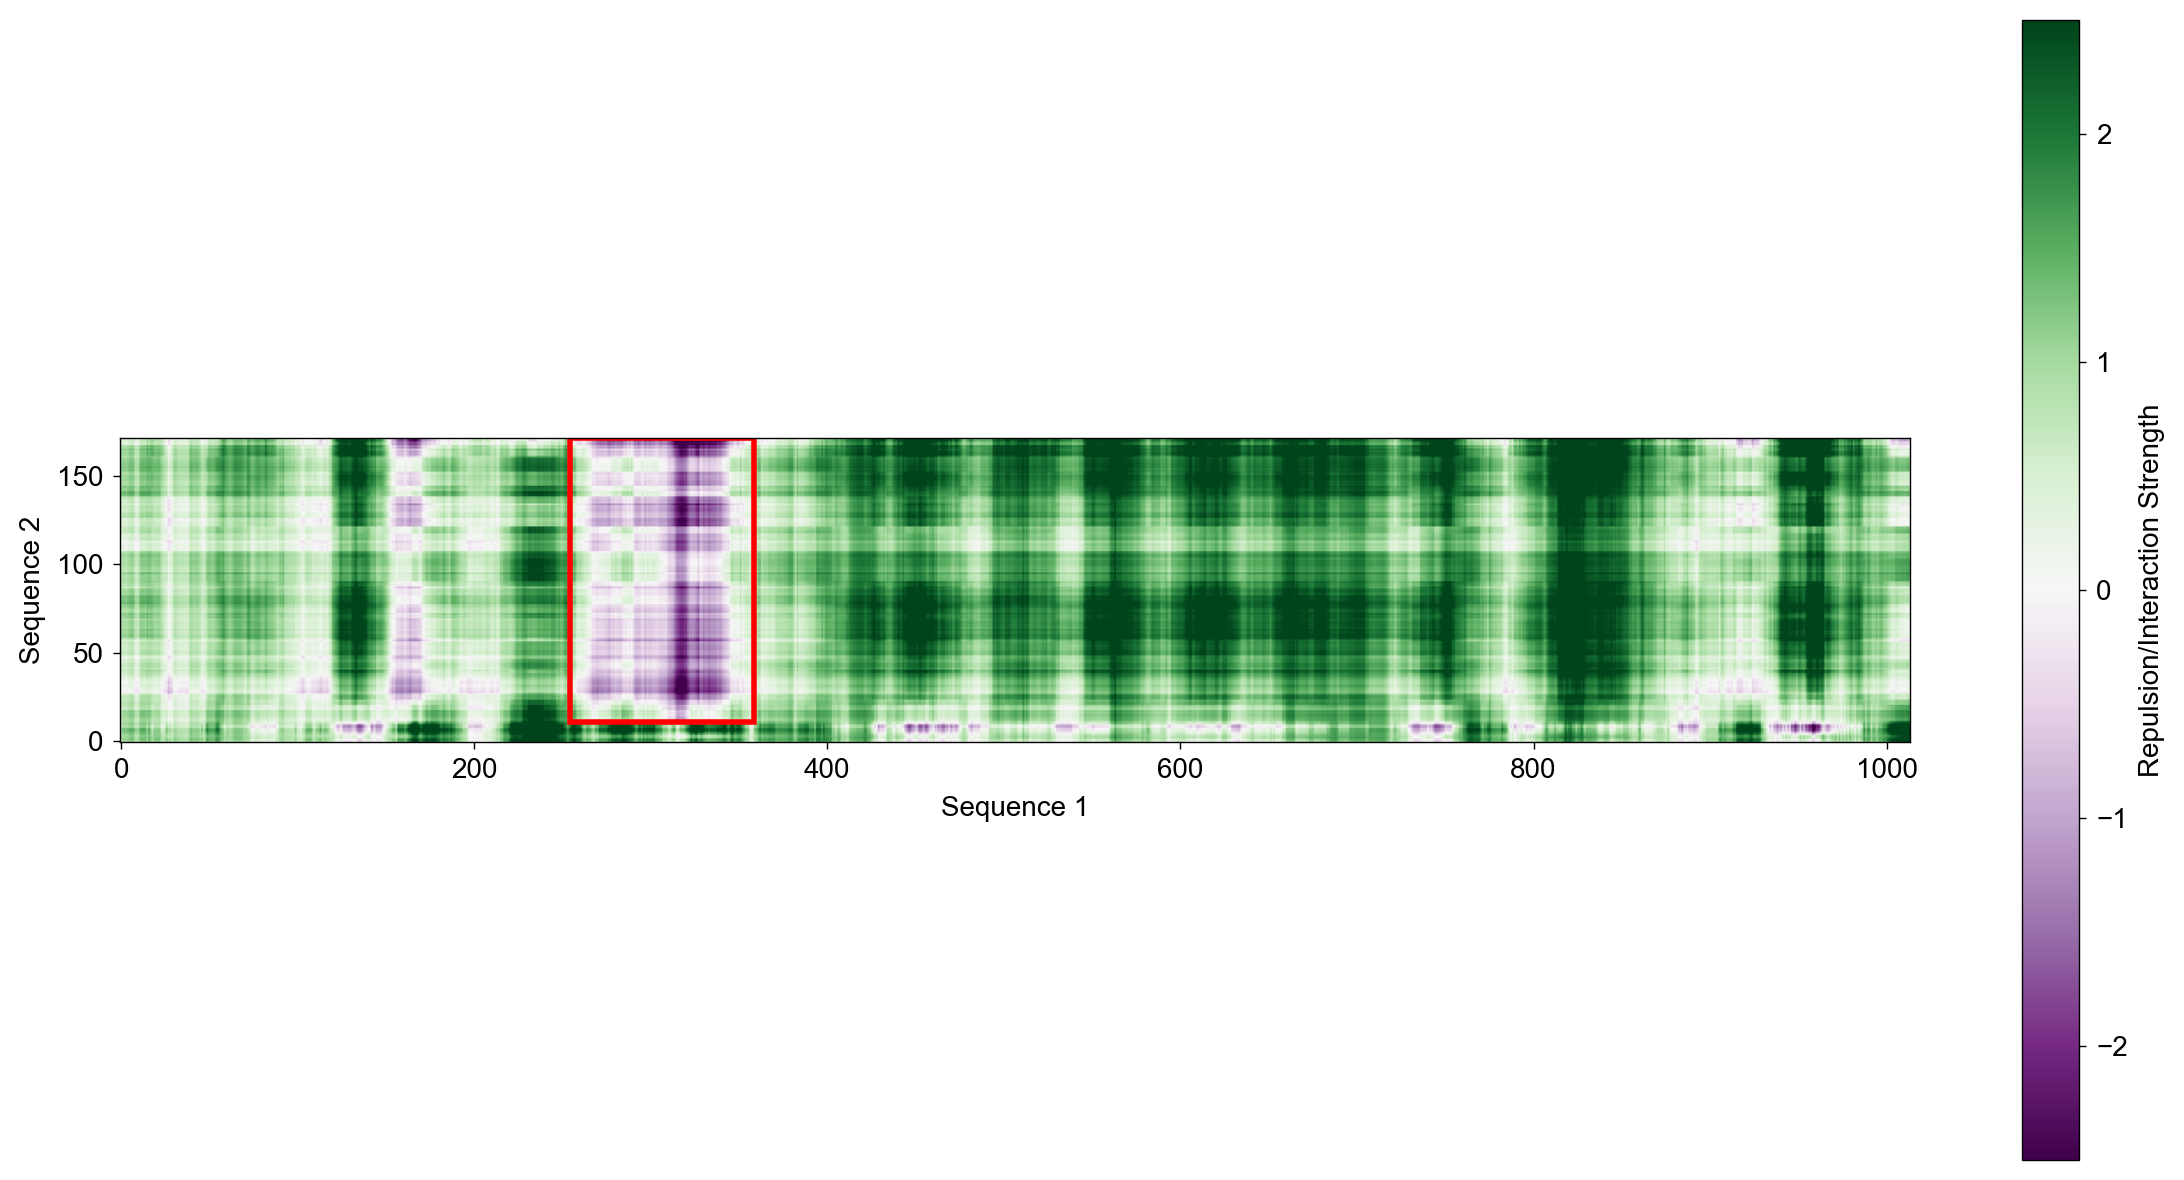

In [16]:
[interactor_pairs, regions, intermap]  = domain_analysis.extract_regions(mf, med1_idr, med14_idr, criteria="less", criteria_threshold=-0.2)
fig, ax = domain_analysis.plot_regions_on_intermap(intermap, [regions], ['r'])

As you can see, it was able to correctly and automatically pull out the strongly interacting region from the interaction map.

Another tool is based on visualizing which letters are involved in strong interaction regions. It colors the residues by amino acid classification and can allow for quick visualization as to the chemical complementarity that matters for the specific interaction. For the above interaction, we might ask what residues and chemical complentarity seem to be driving the interaction for MED1 and MED14's IDRs. The visualization below can help answer this question.

In [17]:
chemical_context_seq_plot(seq=med1_idr, scale_vec=filtered_data, quantile_threshold=0.9)

The magnitude of the size of the letter corresponds to the value of the combined and filtered interaction vectors with med14. The color indicates the class and the greyed text indicates that the interaction was not above a certain threshold. Doing this, we can see the chemical composition of the attractive region is highly positively charged and has some polar residues as well.